# CS781 Phase 2 — L-NER — Arch 4: Efficient Transformer (sliding-window attention + GQA) (`ARCH = "mistral_swa"`)
Adapts **your Phase-1 checkpoint** `<hf-user>/cs781-p1-mistral_swa` (`best/`) to legal NER with exact character spans.

| | |
|---|---|
| Backbone | Phase-1 `MistralForCausalLM` body (`MistralModel`), causal sliding-window attention by default (`ATTN`) |
| Head | dropout + linear token classifier over BIO tags (O + B-/I- × 12 labels = 25 tags) |
| Long documents | sliding windows of `WIN` tokens; overlapping window predictions are averaged per token |
| Methods (`METHOD`) | `full`, `partial` (top-N blocks), `bitfit` (biases + norms), `lora`, `lorma` (LoRMA), `kd` (distillation) |
| Outputs | `submission_<RUN_NAME>.zip` + run files (metrics, predictions, merged weights) in private repo `<hf-user>/cs781-p2` under `runs/<RUN_NAME>/` |

**Before you start**
1. Runtime -> Change runtime type -> **T4 GPU**.
2. Secrets (key icon) -> `HF` = the **same** HF token as Phase 1 (reads your `cs781-p1-*` repos and the gated course dataset).
3. Pick `METHOD` (and a unique `RUN_NAME`) in the first code cell, check *Configuration*, then **Run all**.

Another experiment on the same account: change `METHOD` / `RUN_NAME`, **Run all** again (every run starts from the
Phase-1 checkpoint). `kd` needs a finished teacher run in `cs781-p2` (`TEACHER_RUN`, any architecture — all four
Phase-1 models share one tokenizer, so token positions line up).

Phase-2 rules (capstone §1, §8.2): ≥6 submissions; all four Phase-1 models used; ≥3 different fine-tuning / PEFT
techniques with **LoRMA compulsory**; ≥1 knowledge-distillation run; no two required runs that differ only in
hyperparameters.

In [1]:
ARCH = "mistral_swa"                 # fixed for this notebook
METHOD = "full"                   # "full" | "partial" | "bitfit" | "lora" | "lorma" | "kd"
HEAD = "linear"                   # "linear" (per-token softmax) | "crf" (linear emissions + linear-chain CRF)
RUN_NAME = f"{ARCH}_{METHOD}" + ("" if HEAD == "linear" else f"_{HEAD}")   # unique per experiment

In [2]:
import os, json, math, time, random, zipfile, gc
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from huggingface_hub import login, whoami, HfApi, hf_hub_download, snapshot_download

def get_hf_token():
    try:
        from google.colab import userdata
        return userdata.get("HF")
    except Exception:
        pass
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret("HF")
    except Exception:
        return os.environ["HF_TOKEN"]

HF_TOKEN = get_hf_token()
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)
HF_USER = whoami(token=HF_TOKEN)["name"]
api = HfApi(token=HF_TOKEN)

def hub_push(fn, what, tries=3):
    for t in range(1, tries + 1):
        try:
            fn(); return True
        except Exception as e:
            print(f"  !! {what} upload failed ({t}/{tries}): {e!r}")
            time.sleep(30 * t)
    return False

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
assert DEVICE == "cuda" or os.environ.get("CS781_ALLOW_CPU"), "Switch the runtime to a GPU"
AMP = DEVICE == "cuda"
print(torch.__version__, torch.cuda.get_device_name(0) if AMP else "CPU")
import transformers; print("transformers", transformers.__version__)

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


2.11.0+cu130 Tesla T4
transformers 5.18.0


## Configuration — **all values below are YOUR CHOICE** (document them in the report)

In [3]:
DATASET = "Exploration-Lab/CS-781-Capstone"
P1_REPO = f"{HF_USER}/cs781-p1-{ARCH}"      # Phase-1 checkpoint (best/)
P2_REPO = f"{HF_USER}/cs781-p2"             # all Phase-2 runs: runs/<RUN_NAME>/...
WORK = "/content/p2" if os.path.isdir("/content") else "/tmp/p2"
RUN_DIR = f"{WORK}/{RUN_NAME}"
os.makedirs(RUN_DIR, exist_ok=True)

SEED = 42
VAL_FRAC = 0.15            # documents from fold1+fold2 held out for model selection (same split for every run)

# Context windows over long documents (tokens)
WIN = 512
STRIDE_TRAIN = 256
STRIDE_PRED = 128

# How the backbone attends during fine-tuning
#   decoder-only models: "causal" (as pretrained) or "bidirectional" (full mask; for mistral_swa a ±window band)
ATTN = {"llama": "causal", "prefixlm": "bidirectional", "mistral_swa": "causal", "bart": "n/a"}[ARCH]
#   bart: "encoder" = encoder states only; "decoder" = document fed to encoder AND decoder, decoder states
#   (Phase-1 BART decoder only ever saw positions < TGT_LEN = 256; encoder saw up to 768)
BART_MODE = "encoder"

# Optimisation
EPOCHS = 10
PATIENCE = 3               # stop after this many epochs without a val macro-F1 improvement
MAX_TRAIN_MINUTES = 60     # hard cap on training time; the best epoch so far is kept
BATCH = 16
LR = {"full": 5e-5, "partial": 1e-4, "bitfit": 1e-3, "lora": 5e-4, "lorma": 5e-4, "kd": 1e-4}[METHOD]
HEAD_LR = 1e-3
WEIGHT_DECAY = 0.01
WARMUP_FRAC = 0.06
GRAD_CLIP = 1.0
DROPOUT = 0.1
O_WEIGHT = 1.0             # loss weight of tag "O" (entity tags weigh 1; linear head only)
CRF_BIO_CONSTRAINTS = False   # crf head only: forbid invalid BIO transitions (O -> I-X, B-X / I-X -> I-Y)

# Method-specific
PARTIAL_TRAIN_TOP = 4                   # partial: train only the top-N transformer blocks (+ final norm + head)
ADAPT_TARGETS = ["q_proj", "v_proj"]    # lora / lorma: names of the nn.Linear layers that get adapters
RANK, ALPHA = 8, 16
LORMA_VARIANT = "plus"                  # "plus" = additive-identity rank inflation, "pi" = permutation inflation

# Knowledge distillation (METHOD == "kd"); the student is this notebook's ARCH with fewer Phase-1 blocks
TEACHER_RUN = "llama_full"              # a finished run in P2_REPO
STUDENT_LAYERS = None                   # None = every 2nd block (per stack for bart), or an explicit list
KD_T = 2.0
KD_ALPHA = 0.5                          # loss = KD_ALPHA * CE(gold) + (1 - KD_ALPHA) * T^2 * KL(teacher || student)

# Span decoding: "lenient" = an I-X after O / another type opens an entity; "strict" = only B-X opens one
DECODE = "lenient"
SAVE_WEIGHTS = True                     # merged fine-tuned weights to the Hub (needed if this run is a KD teacher)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

## Data: download, inspect, parse
The raw first record of each file is printed so the format can be checked by eye.

In [4]:
def fetch(rel):
    return hf_hub_download(DATASET, f"Phase_2_LNER/{rel}", repo_type="dataset", token=HF_TOKEN)

for rel in ("Train/fold1-text.json", "Train/fold1-gold.json", "Test/fold3-text.json"):
    raw = json.load(open(fetch(rel), encoding="utf-8"))
    first = raw[next(iter(raw))] if isinstance(raw, dict) else raw[0]
    print(f"{rel}: {type(raw).__name__} of {len(raw)}  first record: {repr(first)[:300]}")

def load_texts(path):
    raw = json.load(open(path, encoding="utf-8"))
    if isinstance(raw, list):
        raw = {r.get("id", r.get("doc_id")): r for r in raw}
    return {str(k): (v if isinstance(v, str) else v.get("text", v.get("document"))) for k, v in raw.items()}

def entity_tuple(x):
    if isinstance(x, (list, tuple)):
        return int(x[0]), int(x[1]), str(x[2]), (x[3] if len(x) > 3 else None)
    s = x.get("start", x.get("start_char", x.get("begin")))
    e = x.get("end", x.get("end_char"))
    lab = x.get("label", x.get("type", x.get("entity")))
    return int(s), int(e), str(lab), x.get("text", x.get("entity_text"))

def load_gold(path):
    raw = json.load(open(path, encoding="utf-8"))
    if isinstance(raw, list):
        raw = {r.get("id", r.get("doc_id")): r for r in raw}
    out = {}
    for k, v in raw.items():
        if isinstance(v, dict):
            v = v.get("entities", v.get("spans", v.get("annotations", [])))
        out[str(k)] = [entity_tuple(x) for x in (v or [])]
    return out

LABELS = [l.strip() for l in open(fetch("Train/labels.txt"), encoding="utf-8") if l.strip()]
assert len(LABELS) == 12, LABELS
TEXTS, GOLD_RAW, FOLD = {}, {}, {}
for f in ("fold1", "fold2"):
    t, g = load_texts(fetch(f"Train/{f}-text.json")), load_gold(fetch(f"Train/{f}-gold.json"))
    assert not (set(t) & set(TEXTS)), "document IDs repeat across folds"
    TEXTS.update(t); FOLD.update({d: f for d in t})
    GOLD_RAW.update({d: g.get(d, []) for d in t})
    print(f"{f}: {len(t)} documents, {sum(len(g.get(d, [])) for d in t)} entities, gold for {len(set(g) & set(t))} docs")
TEST_TEXTS = load_texts(fetch("Test/fold3-text.json"))
print(f"fold3 (test): {len(TEST_TEXTS)} documents")
print("labels:", LABELS)

fold1-text.json:   0%|          | 0.00/1.11M [00:00<?, ?B/s]

Train/fold1-text.json: dict of 35  first record: 'REPORTABLE IN THE SUPREME COURT OF INDIA CRIMINAL APPELLATE JURISDICTION CRIMINAL APPEAL NO. 92/2015 JAGE RAM & ORS. ..Appellants Versus STATE OF HARYANA ..Respondent J U D G M E N T R. BANUMATHI, J. This appeal is preferred against the judgment dated 19.8.2011 passed by the High Court of Punjab an


fold1-gold.json:   0%|          | 0.00/461k [00:00<?, ?B/s]

Train/fold1-gold.json: dict of 35  first record: [[137, 153, 'RESP', 'STATE OF HARYANA'], [252, 261, 'DATE', '19.8.2011'], [276, 308, 'COURT', 'High Court of Punjab and Haryana'], [359, 369, 'COURT', 'High Court'], [575, 585, 'DATE', '18.11.1994'], [637, 644, 'WIT', 'Jagdish'], [695, 704, 'WIT', 'Mange Ram'], [792, 800, 'APP', 'Jage Ram'], [1122, 


fold3-text.json:   0%|          | 0.00/1.19M [00:00<?, ?B/s]

Test/fold3-text.json: dict of 35  first record: 'REPORTABLE IN THE SUPREME COURT OF INDIA CIVIL APPELLATE JURISDICTION CIVIL APPEAL NO.6580 OF 2008 ARISING OUT OF SPECIAL LEAVE PETITION (CIVIL) NO. 15449 OF 2004 ESSCO FABS PVT. LTD. & ANR. ... APPELLANTS VERSUS STATE OF HARYANA & ANR. ... RESPONDENTS WITH CIVIL APPEAL NO.6581 OF 2008 ARISING OUT 


labels.txt:   0%|          | 0.00/71.0 [00:00<?, ?B/s]

fold1: 35 documents, 4120 entities, gold for 35 docs


fold2-text.json:   0%|          | 0.00/1.12M [00:00<?, ?B/s]

fold2-gold.json:   0%|          | 0.00/475k [00:00<?, ?B/s]

fold2: 35 documents, 4273 entities, gold for 35 docs
fold3 (test): 35 documents
labels: ['APP', 'RESP', 'A.COUNSEL', 'R.COUNSEL', 'JUDGE', 'WIT', 'AUTH', 'COURT', 'STAT', 'PREC', 'DATE', 'CASENO']


## Offset convention and gold sanity checks
If the gold records carry the entity text, it tells whether `end` is exclusive (`text[start:end]`) or inclusive.
Internally everything is exclusive; predictions are written back in the gold convention.

In [5]:
hit_ex = hit_in = n_txt = 0
for d, ents in GOLD_RAW.items():
    t = TEXTS[d]
    for s, e, lab, et in ents:
        if et is None: continue
        n_txt += 1; hit_ex += t[s:e] == et; hit_in += t[s:e + 1] == et
END_INCLUSIVE = n_txt > 0 and hit_in > hit_ex
print(f"entity text given for {n_txt} spans: text[s:e] matches {hit_ex}, text[s:e+1] matches {hit_in} "
      f"-> END_INCLUSIVE = {END_INCLUSIVE}")

GOLD, bad = {}, []
for d, ents in GOLD_RAW.items():
    n = len(TEXTS[d]); keep = []
    for s, e, lab, et in ents:
        e2 = e + 1 if END_INCLUSIVE else e
        if lab not in LABELS or not (0 <= s < e2 <= n):
            bad.append((d, s, e, lab)); continue
        keep.append((s, e2, lab))
    GOLD[d] = sorted(set(keep))
print(f"invalid gold spans dropped: {len(bad)}  {bad[:5]}")
mism = [(d, s, e, et, TEXTS[d][s:e + (1 if END_INCLUSIVE else 0)]) for d, ents in GOLD_RAW.items()
        for s, e, lab, et in ents if et is not None and TEXTS[d][s:e + (1 if END_INCLUSIVE else 0)] != et]
print(f"spans whose entity text != document slice: {len(mism)}  {mism[:3]}")

from collections import Counter
cnt = Counter(lab for ents in GOLD.values() for _, _, lab in ents)
lens = [len(TEXTS[d]) for d in TEXTS]
print(f"\ndocument length (chars): min {min(lens)}  median {int(np.median(lens))}  max {max(lens)}")
print("entities per label:", {l: cnt[l] for l in LABELS})

def non_overlapping(ents):
    """BIO cannot encode overlapping spans: keep the earliest-starting (then longest) span of each overlapping group."""
    out, last_end = [], -1
    for s, e, lab in sorted(ents, key=lambda x: (x[0], -(x[1] - x[0]))):
        if s >= last_end:
            out.append((s, e, lab)); last_end = e
    return out
n_ovl = sum(len(GOLD[d]) - len(non_overlapping(GOLD[d])) for d in GOLD)
print(f"overlapping / nested gold spans that BIO cannot represent: {n_ovl}")

entity text given for 8393 spans: text[s:e] matches 8393, text[s:e+1] matches 17 -> END_INCLUSIVE = False
invalid gold spans dropped: 0  []
spans whose entity text != document slice: 0  []

document length (chars): min 10443  median 26620  max 114044
entities per label: {'APP': 407, 'RESP': 381, 'A.COUNSEL': 195, 'R.COUNSEL': 184, 'JUDGE': 245, 'WIT': 187, 'AUTH': 1003, 'COURT': 1013, 'STAT': 1260, 'PREC': 1183, 'DATE': 1575, 'CASENO': 760}
overlapping / nested gold spans that BIO cannot represent: 0


## Train / validation split (by document)

In [6]:
pool = sorted(TEXTS); random.Random(SEED).shuffle(pool)
n_val = max(1, round(VAL_FRAC * len(pool)))
VAL_IDS, TRAIN_IDS = sorted(pool[:n_val]), sorted(pool[n_val:])
print(f"train {len(TRAIN_IDS)} docs  val {len(VAL_IDS)} docs  (val from {Counter(FOLD[d] for d in VAL_IDS)})")

train 60 docs  val 10 docs  (val from Counter({'fold1': 7, 'fold2': 3}))


## Tokenizer, character ↔ token alignment, BIO tags
The Phase-1 tokenizer is byte-level BPE: a token such as `" Court"` carries its leading space, so token character
ranges are trimmed of whitespace. A token's tag comes from the gold span covering its first visible character.

**Oracle check**: gold spans → BIO tags → decoded spans, scored with the official strict metric. Anything below
1.0 is lost before any model is trained (span boundaries inside a token, overlapping spans).

In [7]:
from transformers import PreTrainedTokenizerFast

P1_DIRS = {}
def p1_dir(arch):
    if arch not in P1_DIRS:
        P1_DIRS[arch] = os.path.join(snapshot_download(f"{HF_USER}/cs781-p1-{arch}", token=HF_TOKEN,
                                                       allow_patterns=["best/*"]), "best")
    return P1_DIRS[arch]

tokenizer = PreTrainedTokenizerFast.from_pretrained(p1_dir(ARCH))
tokenizer.model_max_length = 10**9
PAD_ID, VOCAB = tokenizer.pad_token_id, len(tokenizer)
TAGS = ["O"] + [f"{p}-{l}" for l in LABELS for p in ("B", "I")]
tag2id = {t: i for i, t in enumerate(TAGS)}

def tokenize_doc(text):
    enc = tokenizer(text, add_special_tokens=False, return_offsets_mapping=True)
    raw = [tuple(o) for o in enc["offset_mapping"]]
    tr = []
    for s, e in raw:
        while s < e and text[s].isspace(): s += 1
        while e > s and text[e - 1].isspace(): e -= 1
        tr.append((s, e))
    return enc["input_ids"], tr, raw

def bio_tags(text, tr, raw, ents):
    owner = np.full(len(text) + 1, -1, dtype=np.int64)
    for k, (s, e, _) in enumerate(ents):
        owner[s:e] = k
    tags, prev = [], -1
    for (s, e), (rs, _) in zip(tr, raw):
        if s == e:                                     # whitespace-only token: continues an entity, never starts one
            k = owner[rs] if rs < len(text) else -1
            tags.append(tag2id[f"I-{ents[k][2]}"] if k >= 0 and k == prev else 0)
            continue
        k = owner[s]
        tags.append(0 if k < 0 else tag2id[("I-" if k == prev else "B-") + ents[k][2]])
        prev = k
    return tags

def decode(tags, tr):
    spans, cur = [], None
    for t, (s, e) in zip(tags, tr):
        if s == e:                                     # whitespace-only tokens are transparent
            continue
        tag = TAGS[t]
        if tag == "O":
            if cur: spans.append(tuple(cur)); cur = None
            continue
        p, lab = tag.split("-", 1)
        if cur and p == "I" and cur[2] == lab:
            cur[1] = max(cur[1], e)
        else:
            if cur: spans.append(tuple(cur)); cur = None
            if p == "B" or DECODE == "lenient":
                cur = [s, e, lab]
    if cur: spans.append(tuple(cur))
    return sorted(set(spans))

def strict_scores(gold, pred):
    """Same computation as evaluate_phase2.py: per-label strict P/R/F1 over (start, end, label), macro over 12 labels."""
    st = {l: [0, 0, 0] for l in LABELS}
    for d in gold:
        g, p = set(gold[d]), set(pred.get(d, ()))
        for l in LABELS:
            gs = {x for x in g if x[2] == l}; ps = {x for x in p if x[2] == l}
            st[l][0] += len(gs & ps); st[l][1] += len(ps - gs); st[l][2] += len(gs - ps)
    per = {}
    for l, (tp, fp, fn) in st.items():
        pr = tp / (tp + fp) if tp + fp else 0.0; rc = tp / (tp + fn) if tp + fn else 0.0
        per[l] = dict(P=pr, R=rc, F1=2 * pr * rc / (pr + rc) if pr + rc else 0.0, tp=tp, fp=fp, fn=fn)
    return {"F1": float(np.mean([per[l]["F1"] for l in LABELS])), "P": float(np.mean([per[l]["P"] for l in LABELS])),
            "R": float(np.mean([per[l]["R"] for l in LABELS])), "per_label": per}

t0 = time.time()
TOK = {d: tokenize_doc(TEXTS[d]) for d in TEXTS}
TOK.update({d: tokenize_doc(TEST_TEXTS[d]) for d in TEST_TEXTS})
LAB = {d: bio_tags(TEXTS[d], TOK[d][1], TOK[d][2], non_overlapping(GOLD[d])) for d in TEXTS}
ntok = [len(TOK[d][0]) for d in TEXTS]
print(f"tokenised in {time.time()-t0:.0f}s; tokens/doc: median {int(np.median(ntok))}  max {max(ntok)}  "
      f"total train+val {sum(ntok):,}")

oracle = strict_scores(GOLD, {d: decode(LAB[d], TOK[d][1]) for d in TEXTS})
print(f"ORACLE strict macro-F1 {oracle['F1']:.4f}  (P {oracle['P']:.4f}  R {oracle['R']:.4f})")
print("  per-label oracle recall:", {l: round(oracle["per_label"][l]["R"], 4) for l in LABELS})
lost = [(d, s, e, lab) for d in TEXTS for (s, e, lab) in set(GOLD[d]) - set(decode(LAB[d], TOK[d][1]))]
for d, s, e, lab in lost[:8]:
    near = [(a, b) for a, b in TOK[d][1] if b > s - 3 and a < e + 3]
    print(f"  lost {lab:9s} {TEXTS[d][s:e]!r}  tokens: {[TEXTS[d][a:b] for a, b in near]}")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

tokenised in 2s; tokens/doc: median 5533  max 23825  total train+val 460,409
ORACLE strict macro-F1 0.9863  (P 0.9863  R 0.9863)
  per-label oracle recall: {'APP': 0.9828, 'RESP': 0.9816, 'A.COUNSEL': 0.9949, 'R.COUNSEL': 1.0, 'JUDGE': 1.0, 'WIT': 1.0, 'AUTH': 0.986, 'COURT': 0.9822, 'STAT': 0.9802, 'PREC': 0.929, 'DATE': 1.0, 'CASENO': 0.9987}
  lost PREC      'State of M.P. vs. Kashiram & Ors.'  tokens: ['of', 'State', 'of', 'M', '.', 'P', '.', 'vs', '.', 'Kashi', 'ram', '&', 'Ors', '.[', '1', '],']
  lost PREC      'Gambangi Appalaswamy Naldu and Others v. Behara Venkataramanayya Patro [AIR 1984- SC 1728]'  tokens: ['and', 'Gamb', 'angi', 'App', 'al', 'aswamy', 'Nal', 'du', 'and', 'Others', 'v', '.', 'Be', 'hara', 'Venkataram', 'an', 'ayya', 'Pat', 'ro', '[', 'AIR', '1984', '-', 'SC', '17', '28', '].', 'Even']
  lost AUTH      'Railway Board'  tokens: ['of', 'Railway', 'Boards', 'decision']
  lost PREC      'Jatendra Kumar vs. State of Punjab [(1985) 1 SCC 122]'  tokens: ['or', 'Jat

## Windows

In [8]:
def windows(n, win, stride):
    if n <= win:
        return [(0, n)] if n else []
    starts = list(range(0, n - win + 1, stride))
    if starts[-1] + win < n:
        starts.append(n - win)
    return [(a, a + win) for a in starts]

def collate(jobs, with_labels=True):
    L = max(b - a for _, a, b in jobs)
    x = torch.full((len(jobs), L), PAD_ID, dtype=torch.long)
    m = torch.zeros((len(jobs), L), dtype=torch.long)
    y = torch.full((len(jobs), L), -100, dtype=torch.long)
    for i, (d, a, b) in enumerate(jobs):
        x[i, :b - a] = torch.tensor(TOK[d][0][a:b]); m[i, :b - a] = 1
        if with_labels:
            y[i, :b - a] = torch.tensor(LAB[d][a:b])
    return x, m, y

TRAIN_JOBS = [(d, a, b) for d in TRAIN_IDS for a, b in windows(len(TOK[d][0]), WIN, STRIDE_TRAIN)]
print(f"{len(TRAIN_JOBS)} training windows of <= {WIN} tokens  -> {math.ceil(len(TRAIN_JOBS)/BATCH)} steps/epoch")

1476 training windows of <= 512 tokens  -> 93 steps/epoch


## Model: Phase-1 backbone + token-classification head
`HEAD = "crf"`: the linear layer's outputs are emission scores of a linear-chain CRF (Lafferty et al., 2001) with
learned start / end / tag-to-tag transition scores. Training minimises the negative log-likelihood of the gold tag
sequence (forward algorithm), normalised per token so its scale matches the linear head's cross-entropy.
Prediction averages the emission scores of overlapping windows per token, then runs Viterbi over the whole document.
`CRF_BIO_CONSTRAINTS` masks transitions that are invalid in BIO (start-of-window is left unconstrained because
windows can begin inside an entity).

In [9]:
from transformers import LlamaForCausalLM, MistralForCausalLM, BartForConditionalGeneration

def block_stacks(backbone):
    """Lists of transformer blocks in forward order (bart in decoder mode: encoder blocks, then decoder blocks)."""
    if hasattr(backbone, "layers"):
        return [backbone.layers]
    return [backbone.encoder.layers, backbone.decoder.layers]

def keep_blocks(backbone, keep):
    """Student construction: keep a subset of the Phase-1 blocks (applied to every stack)."""
    stacks = []
    for owner in ([backbone] if hasattr(backbone, "layers") else [backbone.encoder, backbone.decoder]):
        idx = keep if keep is not None else list(range(0, len(owner.layers), 2))
        owner.layers = nn.ModuleList([owner.layers[i] for i in idx])
        for j, layer in enumerate(owner.layers):
            for sub in layer.modules():
                if hasattr(sub, "layer_idx"): sub.layer_idx = j
        stacks.append(idx)
    cfg = backbone.config
    if hasattr(cfg, "num_hidden_layers") and hasattr(backbone, "layers"):
        if getattr(cfg, "layer_types", None):
            cfg.layer_types = [cfg.layer_types[i] for i in stacks[0]]
        cfg.num_hidden_layers = len(stacks[0])
    return stacks

class CRF(nn.Module):
    def __init__(self, n_tags, bio_constraints=False):
        super().__init__()
        self.start = nn.Parameter(torch.zeros(n_tags))
        self.end = nn.Parameter(torch.zeros(n_tags))
        self.trans = nn.Parameter(torch.zeros(n_tags, n_tags))          # trans[i, j]: score of tag i followed by tag j
        allowed = torch.ones(n_tags, n_tags, dtype=torch.bool)
        if bio_constraints:
            for j, tj in enumerate(TAGS):
                if tj.startswith("I-"):
                    for i, ti in enumerate(TAGS):
                        if ti == "O" or ti[2:] != tj[2:]:
                            allowed[i, j] = False
        self.register_buffer("allowed", allowed, persistent=False)

    def transitions(self):
        return self.trans.masked_fill(~self.allowed, -1e4)

    def nll(self, em, tags, mask):
        """em (B, L, T) float32 emissions; tags (B, L) with -100 on padding; mask (B, L) bool, real tokens first."""
        trans, B = self.transitions(), em.shape[0]
        tags = tags.clamp(min=0); maskf = mask.float()
        last = tags[torch.arange(B, device=em.device), mask.sum(1) - 1]
        gold = (self.start[tags[:, 0]] + (em.gather(2, tags[..., None]).squeeze(-1) * maskf).sum(1)
                + (trans[tags[:, :-1], tags[:, 1:]] * maskf[:, 1:]).sum(1) + self.end[last])
        alpha = self.start[None] + em[:, 0]                              # forward algorithm, (B, T)
        for t in range(1, em.shape[1]):
            nxt = torch.logsumexp(alpha[:, :, None] + trans[None] + em[:, t, None, :], dim=1)
            alpha = torch.where(mask[:, t, None], nxt, alpha)
        log_z = torch.logsumexp(alpha + self.end[None], dim=1)
        return (log_z - gold).sum() / maskf.sum()

    @torch.no_grad()
    def viterbi(self, em):
        """em (n, T) emissions of one document -> best tag path (list of tag ids)."""
        em, trans = em.double().numpy(), self.transitions().double().cpu().numpy()
        score = self.start.double().cpu().numpy() + em[0]
        back = np.zeros(em.shape, dtype=np.int64)
        for t in range(1, len(em)):
            cand = score[:, None] + trans
            back[t] = cand.argmax(0); score = cand.max(0) + em[t]
        path = [int((score + self.end.double().cpu().numpy()).argmax())]
        for t in range(len(em) - 1, 0, -1):
            path.append(int(back[t, path[-1]]))
        return path[::-1]

class Tagger(nn.Module):
    def __init__(self, arch, attn, bart_mode, layers="all", head="linear", crf_constraints=False):
        super().__init__()
        self.arch, self.attn, self.bart_mode, self.head_type = arch, attn, bart_mode, head
        d = p1_dir(arch)
        if arch == "bart":
            full = BartForConditionalGeneration.from_pretrained(d).float()
            self.backbone = full.model.encoder if bart_mode == "encoder" else full.model
            hidden = full.config.d_model
        else:
            cls = MistralForCausalLM if arch == "mistral_swa" else LlamaForCausalLM
            full = cls.from_pretrained(d).float()
            self.backbone = full.model
            hidden = full.config.hidden_size
        self.window = getattr(full.config, "sliding_window", None) if arch == "mistral_swa" else None
        self.kept = None if layers == "all" else keep_blocks(self.backbone, layers)
        self.drop = nn.Dropout(DROPOUT)
        self.head = nn.Linear(hidden, len(TAGS))
        self.crf = CRF(len(TAGS), crf_constraints) if head == "crf" else None

    def forward(self, input_ids, attention_mask):
        if self.arch == "bart":
            if self.bart_mode == "encoder":
                h = self.backbone(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
            else:
                h = self.backbone(input_ids=input_ids, attention_mask=attention_mask, decoder_input_ids=input_ids,
                                  decoder_attention_mask=attention_mask, use_cache=False).last_hidden_state
        else:
            mask = attention_mask
            if self.attn == "bidirectional":
                B, L = input_ids.shape
                mask = attention_mask.bool()[:, None, None, :].expand(B, 1, L, L)     # True = attend; pad keys off
                if self.window:
                    i = torch.arange(L, device=input_ids.device)
                    mask = mask & ((i[:, None] - i[None, :]).abs() < self.window)
            h = self.backbone(input_ids=input_ids, attention_mask=mask, use_cache=False).last_hidden_state
        return self.head(self.drop(h))

def n_params(m, trainable=False):
    return sum(p.numel() for p in m.parameters() if p.requires_grad or not trainable)

STUDENT = METHOD == "kd"
model = Tagger(ARCH, ATTN, BART_MODE, layers=STUDENT_LAYERS if STUDENT else "all", head=HEAD,
               crf_constraints=CRF_BIO_CONSTRAINTS).to(DEVICE)
print(f"{ARCH} tagger ({HEAD} head): {n_params(model)/1e6:.1f}M parameters"
      + (f"  (student, kept blocks {model.kept})" if STUDENT else ""))

Loading weights:   0%|          | 0/110 [00:00<?, ?it/s]

mistral_swa tagger (linear head): 100.1M parameters


## Sanity checks: attention direction and padding
Changing token 40 must change the outputs at positions < 40 only if the model sees right context; appending
padding must not change the outputs of real tokens.

In [10]:
@torch.no_grad()
def attention_checks(net):
    net.eval()
    d = max(TRAIN_IDS, key=lambda k: len(TOK[k][0]))
    x = torch.tensor([TOK[d][0][:64]], device=DEVICE); m = torch.ones_like(x)
    x2 = x.clone(); x2[0, 40] = (x2[0, 40] + 1) % VOCAB
    a, b = net(x, m).float(), net(x2, m).float()
    left, here = (a[0, :40] - b[0, :40]).abs().max().item(), (a[0, 40] - b[0, 40]).abs().max().item()
    sees_right = left > 1e-4
    expect = net.arch == "bart" or net.attn == "bidirectional"
    xp = torch.cat([x, torch.full((1, 8), PAD_ID, device=DEVICE)], 1)
    mp = torch.cat([m, torch.zeros((1, 8), dtype=m.dtype, device=DEVICE)], 1)
    pad_ok = torch.allclose(a, net(xp, mp).float()[:, :64], atol=1e-4)
    print(f"{net.arch} (attn={net.attn}, bart_mode={net.bart_mode}): changing token 40 moves outputs at positions <40 by "
          f"{left:.2e}, at 40 by {here:.2e} -> sees right context: {sees_right} (expected {expect}); "
          f"padding-invariant: {pad_ok}")
    if net.arch == "bart":
        enc = net.backbone if net.bart_mode == "encoder" else net.backbone.encoder
        e1 = enc(input_ids=x, attention_mask=m).last_hidden_state.float()
        e2 = enc(input_ids=x2, attention_mask=m).last_hidden_state.float()
        print(f"  bart encoder alone: positions <40 move by {(e1[0, :40] - e2[0, :40]).abs().max().item():.2e}, "
              f"position 40 by {(e1[0, 40] - e2[0, 40]).abs().max().item():.2e}  (encoder output scale "
              f"{e1.abs().mean().item():.2e})")
    assert pad_ok, "padding changes the outputs of real tokens"
    if sees_right != expect:
        if net.arch != "bart":
            raise AssertionError("attention mask is not applied as intended")
        print("  !! measured property of the Phase-1 BART checkpoint (right context barely reaches earlier positions);"
              " training continues — record these numbers")
    net.train()

attention_checks(model)

mistral_swa (attn=causal, bart_mode=encoder): changing token 40 moves outputs at positions <40 by 0.00e+00, at 40 by 2.46e+00 -> sees right context: False (expected False); padding-invariant: True


## Fine-tuning / adaptation method
* **LoRA** (Hu et al., 2021): `h = W0 x + (α/r)·B(A x)`, `B = 0` at init.
* **LoRMA** (Bihany, Patel & Modi, 2025): multiplicative update `h = 𝓘(BA)·W0 x`.
  `plus`: `𝓘(BA) = I + (α/r)·BA`, computed as `W0x + (α/r)·B(A(W0x))` without forming `BA` (`B = 0` at init).
  `pi`: `𝓘(BA)` rotates row *i* of `BA` cyclically by *i*; init (first column of `B` = 1, `A = e₀e₀ᵀ`) gives `𝓘(BA) = I`.
  The bias (BART only) is added after the multiplicative transform.
Both merge into a plain `nn.Linear` after training (no inference overhead); the merge is checked numerically.

In [11]:
class LoRALinear(nn.Module):
    def __init__(self, base, r, alpha):
        super().__init__()
        self.base, self.s = base, alpha / r
        self.A = nn.Parameter(torch.empty(r, base.in_features)); nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        self.B = nn.Parameter(torch.zeros(base.out_features, r))

    def forward(self, x):
        return self.base(x) + self.s * F.linear(F.linear(x, self.A), self.B)

    def merged_weight(self):
        return self.base.weight + self.s * self.B @ self.A

class LoRMALinear(nn.Module):
    def __init__(self, base, r, alpha, variant):
        super().__init__()
        self.base, self.variant, d = base, variant, base.out_features
        self.A = nn.Parameter(torch.zeros(r, d)); self.B = nn.Parameter(torch.zeros(d, r))
        if variant == "plus":
            self.s = alpha / r
            nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        else:
            self.s = 1.0
            nn.init.kaiming_uniform_(self.B, a=math.sqrt(5))
            with torch.no_grad():
                self.B[:, 0] = 1.0; self.A[0, 0] = 1.0
            rot = (torch.arange(d)[None, :] - torch.arange(d)[:, None]) % d     # T[i, j] = (BA)[i, (j - i) mod d]
            self.register_buffer("rot", rot, persistent=False)

    def transform(self):                                                        # pi only: 𝓘(BA), d x d
        return torch.gather(self.B @ self.A, 1, self.rot)

    def forward(self, x):
        y0 = F.linear(x, self.base.weight)
        y = y0 + self.s * F.linear(F.linear(y0, self.A), self.B) if self.variant == "plus" \
            else F.linear(y0, self.transform())
        return y if self.base.bias is None else y + self.base.bias

    def merged_weight(self):
        W0 = self.base.weight
        return W0 + self.s * self.B @ (self.A @ W0) if self.variant == "plus" else self.transform() @ W0

ADAPTERS = (LoRALinear, LoRMALinear)

def inject(net, make):
    n = 0
    for mod in list(net.backbone.modules()):
        for cname, child in list(mod.named_children()):
            if isinstance(child, nn.Linear) and cname in ADAPT_TARGETS:
                setattr(mod, cname, make(child)); n += 1
    return n

def merge_adapters(net):
    for mod in list(net.modules()):
        for cname, child in list(mod.named_children()):
            if isinstance(child, ADAPTERS):
                lin = child.base
                with torch.no_grad():
                    lin.weight.copy_(child.merged_weight())
                setattr(mod, cname, lin)

def head_params(net):
    return list(net.head.parameters()) + (list(net.crf.parameters()) if net.crf is not None else [])

def configure(net, method):
    for p in net.parameters():
        p.requires_grad = method in ("full", "kd")
    for p in head_params(net):
        p.requires_grad = True
    if method == "partial":
        blocks = [b for stack in block_stacks(net.backbone) for b in stack]
        for b in blocks[-PARTIAL_TRAIN_TOP:]:
            for p in b.parameters(): p.requires_grad = True
        if hasattr(net.backbone, "norm"):
            for p in net.backbone.norm.parameters(): p.requires_grad = True
    elif method == "bitfit":
        for n, p in net.backbone.named_parameters():
            if n.endswith(".bias") or "norm" in n.lower():
                p.requires_grad = True
    elif method in ("lora", "lorma"):
        x, m, _ = collate(TRAIN_JOBS[:2]); x, m = x.to(DEVICE), m.to(DEVICE)
        net.eval()
        with torch.no_grad(): ref = net(x, m).float()
        make = (lambda lin: LoRALinear(lin, RANK, ALPHA)) if method == "lora" else \
               (lambda lin: LoRMALinear(lin, RANK, ALPHA, LORMA_VARIANT))
        k = inject(net, make); net.to(DEVICE)
        with torch.no_grad(): diff = (net(x, m).float() - ref).abs().max().item()
        print(f"{method}: adapters on {k} linear layers {ADAPT_TARGETS}; output change at init {diff:.2e}")
        assert diff < 1e-3, "adapter is not identity at initialisation"
        net.train()
        for mod in net.modules():
            if isinstance(mod, ADAPTERS):
                mod.A.requires_grad = True; mod.B.requires_grad = True

configure(model, METHOD)
TOTAL_PARAMS, TRAINABLE_PARAMS = n_params(model), n_params(model, trainable=True)
print(f"METHOD={METHOD}: trainable {TRAINABLE_PARAMS/1e6:.3f}M of {TOTAL_PARAMS/1e6:.1f}M "
      f"({100*TRAINABLE_PARAMS/TOTAL_PARAMS:.2f}%)")

METHOD=full: trainable 100.112M of 100.1M (100.00%)


## Prediction (sliding windows, per-token averaged probabilities -> BIO decode -> character spans)

In [12]:
@torch.no_grad()
def predict(net, doc_ids, stride=STRIDE_PRED, bs=BATCH * 2):
    was_training = net.training; net.eval()
    jobs = [(d, a, b) for d in doc_ids for a, b in windows(len(TOK[d][0]), WIN, stride)]
    acc = {d: torch.zeros(len(TOK[d][0]), len(TAGS)) for d in doc_ids}
    cnt = {d: torch.zeros(len(TOK[d][0]), 1) for d in doc_ids}
    for i in range(0, len(jobs), bs):
        chunk = jobs[i:i + bs]
        x, m, _ = collate(chunk, with_labels=False)
        with torch.autocast(DEVICE, dtype=torch.float16, enabled=AMP):
            p = net(x.to(DEVICE), m.to(DEVICE)).float()
            p = (p if net.crf is not None else p.softmax(-1)).cpu()     # crf: average emissions; linear: probabilities
        for (d, a, b), pi in zip(chunk, p):
            acc[d][a:b] += pi[:b - a]; cnt[d][a:b] += 1
    net.train(was_training)
    out = {}
    for d in doc_ids:
        avg = acc[d] / cnt[d].clamp(min=1)
        tags = (net.crf.viterbi(avg) if net.crf is not None else avg.argmax(-1).tolist()) if len(avg) else []
        out[d] = decode(tags, TOK[d][1])
    return out

## Knowledge-distillation teacher (only when `METHOD == "kd"`)

In [13]:
teacher, teacher_info = None, None
if METHOD == "kd":
    teacher_info = json.load(open(hf_hub_download(P2_REPO, f"runs/{TEACHER_RUN}/run_config.json", token=HF_TOKEN)))
    assert teacher_info["tags"] == TAGS, "teacher was trained with a different tag set"
    if sorted(teacher_info["val_ids"]) != VAL_IDS:
        print("!! teacher used a different validation split: it may have been trained on this run's val documents")
    teacher = Tagger(teacher_info["arch"], teacher_info["attn"], teacher_info["bart_mode"],
                     layers=teacher_info["layers"], head=teacher_info.get("head", "linear"),
                     crf_constraints=teacher_info.get("crf_bio_constraints", False))
    sd = torch.load(hf_hub_download(P2_REPO, f"runs/{TEACHER_RUN}/model.pt", token=HF_TOKEN),
                    map_location="cpu", weights_only=True)
    teacher.load_state_dict(sd); del sd
    teacher.to(DEVICE).eval()
    for p in teacher.parameters(): p.requires_grad = False
    t0 = time.time(); teacher_val = strict_scores({d: GOLD[d] for d in VAL_IDS}, predict(teacher, VAL_IDS))
    teacher_val_seconds = time.time() - t0
    print(f"teacher {TEACHER_RUN}: {teacher_info['arch']}/{teacher_info['method']}, {n_params(teacher)/1e6:.1f}M params, "
          f"val macro-F1 {teacher_val['F1']:.4f} (stored {teacher_info['val']['F1']:.4f}), val inference "
          f"{teacher_val_seconds:.1f}s  ->  student {n_params(model)/1e6:.1f}M params")

## Training (model selection on validation strict macro-F1)

In [14]:
head_ids = {id(p) for p in head_params(model)}
named = [(n, p) for n, p in model.named_parameters() if p.requires_grad]
groups = [{"params": [p for n, p in named if id(p) in head_ids], "lr": HEAD_LR, "weight_decay": WEIGHT_DECAY},
          {"params": [p for n, p in named if id(p) not in head_ids and p.dim() >= 2], "lr": LR, "weight_decay": WEIGHT_DECAY},
          {"params": [p for n, p in named if id(p) not in head_ids and p.dim() < 2], "lr": LR, "weight_decay": 0.0}]
groups = [g for g in groups if g["params"]]
for g in groups: g["base_lr"] = g["lr"]
opt = torch.optim.AdamW(groups, betas=(0.9, 0.999), fused=AMP)
scaler = torch.amp.GradScaler(DEVICE, enabled=AMP)
class_w = torch.ones(len(TAGS), device=DEVICE); class_w[0] = O_WEIGHT

steps_per_epoch = math.ceil(len(TRAIN_JOBS) / BATCH)
total_steps = EPOCHS * steps_per_epoch
warmup = max(1, int(WARMUP_FRAC * total_steps))
lr_mult = lambda s: (s + 1) / warmup if s < warmup else max(0.0, (total_steps - s) / max(1, total_steps - warmup))

history, best, best_state, bad, step = [], {"F1": -1.0}, None, 0, 0
if AMP: torch.cuda.reset_peak_memory_stats()
t_start = time.time(); train_seconds = 0.0; stop = False
for epoch in range(1, EPOCHS + 1):
    t_ep = time.time(); order = np.random.permutation(len(TRAIN_JOBS)); losses = []
    for i in range(0, len(order), BATCH):
        x, m, y = collate([TRAIN_JOBS[j] for j in order[i:i + BATCH]])
        x, m, y = x.to(DEVICE), m.to(DEVICE), y.to(DEVICE)
        for g in opt.param_groups: g["lr"] = g["base_lr"] * lr_mult(step)
        with torch.autocast(DEVICE, dtype=torch.float16, enabled=AMP):
            logits = model(x, m)
        logits = logits.float()
        valid = y != -100
        if model.crf is not None:
            loss = model.crf.nll(logits, y, valid)
        else:
            loss = F.cross_entropy(logits.view(-1, len(TAGS)), y.view(-1), weight=class_w, ignore_index=-100)
        if teacher is not None:                     # distils the per-token softmax of the emissions (both head types)
            with torch.no_grad(), torch.autocast(DEVICE, dtype=torch.float16, enabled=AMP):
                t_logits = teacher(x, m)
            kl = F.kl_div(F.log_softmax(logits[valid] / KD_T, -1), F.softmax(t_logits.float()[valid] / KD_T, -1),
                          reduction="batchmean") * KD_T ** 2
            loss = KD_ALPHA * loss + (1 - KD_ALPHA) * kl
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_([p for _, p in named], GRAD_CLIP)
        scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
        losses.append(loss.item()); step += 1
        if (time.time() - t_start) / 60 > MAX_TRAIN_MINUTES:
            stop = True; break
    train_seconds += time.time() - t_ep
    val = strict_scores({d: GOLD[d] for d in VAL_IDS}, predict(model, VAL_IDS))
    history.append({"epoch": epoch, "step": step, "train_loss": float(np.mean(losses)), "val_F1": val["F1"],
                    "val_P": val["P"], "val_R": val["R"], "minutes": (time.time() - t_start) / 60})
    print(f"epoch {epoch}: loss {np.mean(losses):.4f}  val macro-F1 {val['F1']:.4f}  P {val['P']:.4f}  R {val['R']:.4f}  "
          f"({time.time()-t_ep:.0f}s)")
    if val["F1"] > best["F1"]:
        best = {k: val[k] for k in ("F1", "P", "R")} | {"epoch": epoch}
        best_state = {k: v.detach().to("cpu", copy=True) for k, v in model.state_dict().items()}; bad = 0
    else:
        bad += 1
    if stop or bad >= PATIENCE:
        print("stopping:", "time cap" if stop else f"no improvement for {PATIENCE} epochs"); break
PEAK_MEM_GB = torch.cuda.max_memory_allocated() / 1e9 if AMP else float("nan")
print(f"best epoch {best['epoch']}: val macro-F1 {best['F1']:.4f};  train time {train_seconds/60:.1f} min;  "
      f"peak GPU memory {PEAK_MEM_GB:.2f} GB")

epoch 1: loss 0.6189  val macro-F1 0.2422  P 0.2205  R 0.2769  (45s)
epoch 2: loss 0.0497  val macro-F1 0.2925  P 0.2597  R 0.3526  (46s)
epoch 3: loss 0.0190  val macro-F1 0.2888  P 0.2614  R 0.3328  (47s)
epoch 4: loss 0.0076  val macro-F1 0.3206  P 0.2859  R 0.3768  (48s)
epoch 5: loss 0.0029  val macro-F1 0.3121  P 0.2810  R 0.3590  (48s)
epoch 6: loss 0.0013  val macro-F1 0.3115  P 0.2819  R 0.3562  (48s)
epoch 7: loss 0.0010  val macro-F1 0.3146  P 0.2904  R 0.3508  (48s)
stopping: no improvement for 3 epochs
best epoch 4: val macro-F1 0.3206;  train time 4.9 min;  peak GPU memory 5.83 GB


## Best epoch -> merge adapters -> validation report

In [15]:
model.load_state_dict(best_state)
model.eval()
xv, mv, _ = collate([(d, a, b) for d in VAL_IDS[:2] for a, b in windows(len(TOK[d][0]), WIN, WIN)][:4])
xv, mv = xv.to(DEVICE), mv.to(DEVICE)
with torch.no_grad():
    before = model(xv, mv).float()
    merge_adapters(model)
    merge_diff = (model(xv, mv).float() - before).abs().max().item()
print(f"adapter merge: max |logit change| = {merge_diff:.2e}")
assert merge_diff < 1e-2 * max(1.0, before.abs().max().item())

t0 = time.time(); VAL_PRED = predict(model, VAL_IDS); val_seconds = time.time() - t0
VAL_GOLD = {d: GOLD[d] for d in VAL_IDS}
val = strict_scores(VAL_GOLD, VAL_PRED)
print(f"VALIDATION strict macro-F1 {val['F1']:.4f}  P {val['P']:.4f}  R {val['R']:.4f}   ({val_seconds:.1f}s)")
print(f"{'label':10s} {'P':>7s} {'R':>7s} {'F1':>7s} {'gold':>6s} {'pred':>6s}")
for l in LABELS:
    r = val["per_label"][l]
    print(f"{l:10s} {r['P']:7.4f} {r['R']:7.4f} {r['F1']:7.4f} {r['tp']+r['fn']:6d} {r['tp']+r['fp']:6d}")

adapter merge: max |logit change| = 0.00e+00
VALIDATION strict macro-F1 0.3206  P 0.2859  R 0.3768   (5.1s)
label            P       R      F1   gold   pred
APP         0.0625  0.0641  0.0633     78     80
RESP        0.1333  0.2759  0.1798     58    120
A.COUNSEL   0.2299  0.3774  0.2857     53     87
R.COUNSEL   0.2468  0.3585  0.2923     53     77
JUDGE       0.3140  0.5625  0.4030     48     86
WIT         0.0000  0.0000  0.0000     28     35
AUTH        0.0722  0.0769  0.0745     91     97
COURT       0.8405  0.9257  0.8810    148    163
STAT        0.3348  0.3598  0.3468    214    230
PREC        0.1207  0.2333  0.1591    210    406
DATE        0.8169  0.8673  0.8413    324    344
CASENO      0.2591  0.4201  0.3205    169    274


## Error breakdown on validation (counts only — interpretation is yours)
Each predicted span that is not an exact match is put in one category: same span / wrong label; same label /
wrong boundary (overlaps a gold span); wrong boundary and label; spurious (overlaps no gold span). Gold spans
with no overlapping prediction are *missed*.

In [16]:
def overlap(a, b):
    return a[0] < b[1] and b[0] < a[1]
cats = Counter(); confusion = Counter()
for d in VAL_IDS:
    g, p = set(VAL_GOLD[d]), set(VAL_PRED[d])
    gspan = {(s, e): lab for s, e, lab in g}
    for s, e, lab in p:
        if (s, e, lab) in g: cats["exact"] += 1
        elif (s, e) in gspan: cats["right span, wrong label"] += 1; confusion[(gspan[(s, e)], lab)] += 1
        else:
            ov = [x for x in g if overlap(x, (s, e))]
            if any(x[2] == lab for x in ov): cats["right label, wrong boundary"] += 1
            elif ov: cats["wrong boundary and label"] += 1
            else: cats["spurious"] += 1
    cats["missed (no overlapping prediction)"] += sum(1 for x in g if not any(overlap(x, y) for y in p))
for k, v in cats.most_common(): print(f"  {k:36s} {v}")
print("most frequent label confusions (gold -> predicted):", confusion.most_common(8))

  exact                                709
  right label, wrong boundary          656
  spurious                             411
  missed (no overlapping prediction)   224
  wrong boundary and label             196
  right span, wrong label              27
most frequent label confusions (gold -> predicted): [(('R.COUNSEL', 'A.COUNSEL'), 7), (('RESP', 'PREC'), 4), (('APP', 'PREC'), 3), (('APP', 'RESP'), 2), (('A.COUNSEL', 'R.COUNSEL'), 2), (('DATE', 'CASENO'), 1), (('PREC', 'COURT'), 1), (('CASENO', 'PREC'), 1)]


## Test predictions -> `prediction.json` -> `submission.zip`

In [17]:
t0 = time.time(); TEST_PRED = predict(model, sorted(TEST_TEXTS)); test_seconds = time.time() - t0
off = 1 if END_INCLUSIVE else 0
prediction = {d: [[int(s), int(e) - off, lab] for s, e, lab in sorted(set(TEST_PRED.get(d, []))) if e - off > s]
              for d in TEST_TEXTS}                  # the evaluator requires start < end

# same checks as the official evaluator
assert set(prediction) == set(TEST_TEXTS)
for d, ents in prediction.items():
    seen = set()
    for s, e, lab in ents:
        assert isinstance(s, int) and isinstance(e, int) and 0 <= s < e and lab in LABELS, (d, s, e, lab)
        assert (s, e, lab) not in seen; seen.add((s, e, lab))
print(f"test: {len(prediction)} documents, {sum(map(len, prediction.values()))} entities  ({test_seconds:.1f}s)")
print("predicted entities per label:", dict(Counter(x[2] for v in prediction.values() for x in v)))

json.dump(prediction, open(f"{RUN_DIR}/prediction.json", "w", encoding="utf-8"), ensure_ascii=False)
ZIP = f"{RUN_DIR}/submission_{RUN_NAME}.zip"
with zipfile.ZipFile(ZIP, "w", zipfile.ZIP_DEFLATED) as z:
    z.write(f"{RUN_DIR}/prediction.json", arcname="prediction.json")
with zipfile.ZipFile(ZIP) as z:
    assert z.namelist() == ["prediction.json"]
print("wrote", ZIP)

test: 35 documents, 5141 entities  (17.1s)
predicted entities per label: {'CASENO': 477, 'APP': 200, 'RESP': 182, 'JUDGE': 156, 'DATE': 763, 'COURT': 587, 'PREC': 1123, 'AUTH': 321, 'STAT': 978, 'A.COUNSEL': 154, 'R.COUNSEL': 103, 'WIT': 97}
wrote /content/p2/mistral_swa_full/submission_mistral_swa_full.zip


## Save the run (report numbers, predictions, merged weights) and download the submission

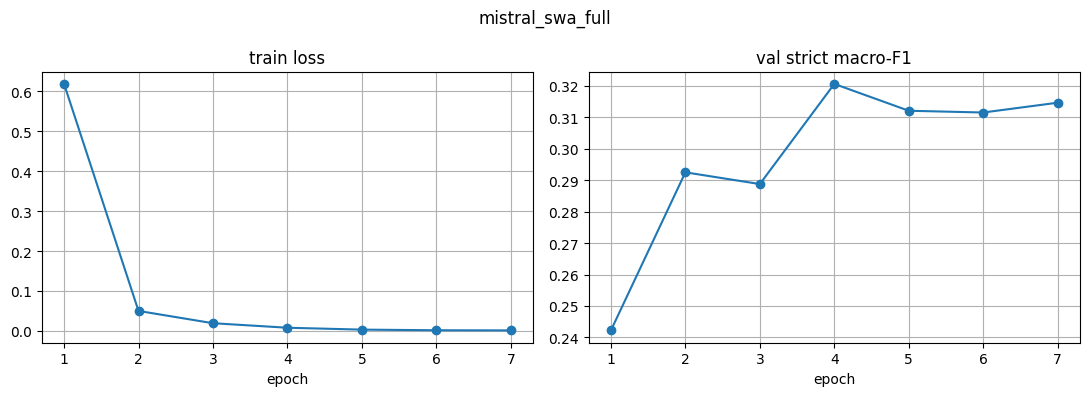

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

{
 "run": "mistral_swa_full",
 "params_total": 100111897,
 "params_trainable": 100111897,
 "train_minutes": 4.929499351978302,
 "peak_gpu_gb": 5.825288192,
 "best_epoch": 4,
 "oracle_F1": 0.986284164100113,
 "val": {
  "F1": 0.3206139482275772,
  "P": 0.285878140708762,
  "R": 0.37678842946072005
 }
}


In [18]:
info = {
    "run": RUN_NAME, "arch": ARCH, "method": METHOD, "attn": ATTN, "bart_mode": BART_MODE,
    "layers": STUDENT_LAYERS if STUDENT else "all", "head": HEAD, "crf_bio_constraints": CRF_BIO_CONSTRAINTS,
    "kept_blocks": model.kept, "tags": TAGS, "val_ids": VAL_IDS, "end_inclusive": END_INCLUSIVE,
    "config": {k: globals()[k] for k in ("SEED", "VAL_FRAC", "WIN", "STRIDE_TRAIN", "STRIDE_PRED", "EPOCHS", "PATIENCE",
                                         "MAX_TRAIN_MINUTES", "BATCH", "LR", "HEAD_LR", "WEIGHT_DECAY", "WARMUP_FRAC",
                                         "GRAD_CLIP", "DROPOUT", "O_WEIGHT", "PARTIAL_TRAIN_TOP", "ADAPT_TARGETS",
                                         "RANK", "ALPHA", "LORMA_VARIANT", "TEACHER_RUN", "STUDENT_LAYERS", "KD_T",
                                         "KD_ALPHA", "DECODE")},
    "params_total": TOTAL_PARAMS, "params_trainable": TRAINABLE_PARAMS, "params_final": n_params(model),
    "train_minutes": train_seconds / 60, "peak_gpu_gb": PEAK_MEM_GB, "best_epoch": best["epoch"],
    "val_predict_seconds": val_seconds, "test_predict_seconds": test_seconds, "oracle_F1": oracle["F1"],
    "val": {k: val[k] for k in ("F1", "P", "R")}, "val_per_label": val["per_label"], "error_breakdown": dict(cats),
    "teacher": teacher_info and {"run": TEACHER_RUN, "arch": teacher_info["arch"], "method": teacher_info["method"],
                                 "params": teacher_info["params_final"], "val_F1": teacher_val["F1"],
                                 "val_predict_seconds": teacher_val_seconds},
    "history": history,
}
json.dump(info, open(f"{RUN_DIR}/run_config.json", "w"), indent=1)
json.dump({d: [list(x) for x in VAL_PRED[d]] for d in VAL_IDS}, open(f"{RUN_DIR}/val_pred.json", "w"))
json.dump({d: [list(x) for x in VAL_GOLD[d]] for d in VAL_IDS}, open(f"{RUN_DIR}/val_gold.json", "w"))
if SAVE_WEIGHTS:
    torch.save(model.state_dict(), f"{RUN_DIR}/model.pt")

import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot([h["epoch"] for h in history], [h["train_loss"] for h in history], marker="o"); ax[0].set_title("train loss")
ax[1].plot([h["epoch"] for h in history], [h["val_F1"] for h in history], marker="o"); ax[1].set_title("val strict macro-F1")
for a in ax: a.set_xlabel("epoch"); a.grid(True)
fig.suptitle(RUN_NAME); plt.tight_layout(); plt.savefig(f"{RUN_DIR}/curves.png", dpi=130); plt.show()

api.create_repo(P2_REPO, private=True, exist_ok=True)
hub_push(lambda: api.upload_folder(folder_path=RUN_DIR, path_in_repo=f"runs/{RUN_NAME}", repo_id=P2_REPO,
                                   commit_message=f"{RUN_NAME} val F1 {val['F1']:.4f}"), f"runs/{RUN_NAME}")
try:
    from google.colab import files
    files.download(ZIP)
except Exception:
    pass
print(json.dumps({k: info[k] for k in ("run", "params_total", "params_trainable", "train_minutes", "peak_gpu_gb",
                                       "best_epoch", "oracle_F1", "val")}, indent=1))